# Canteen Food Waste Forecasting with a Stacking Ensemble (Kaggle Canteen Dataset)

This notebook applies the method of `canteen_methodology.ipynb` to `datasets/canteen_dataset.csv`, which records the daily food waste (kg) of a canteen for each meal, canteen section and food category. It compares six models: Random Forest, XGBoost, SVR, LSTM, and two stacking ensembles that combine them through a Ridge regression meta-learner.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and data quality checks |
| 2 | Feature engineering: date features and lagged waste |
| 3 | Data analysis |
| 4 | One-hot encoding, train/test split, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. On Google Colab the GitHub repository is cloned first;
# when run locally, the notebook already sits next to the dataset in the repository folder.
import os, sys
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/canteen_dataset.csv"

if "google.colab" in sys.modules and not os.path.exists(DATA_PATH):
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the train/test split and the tree models
TEST_SIZE         = 0.20      # share of rows held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding records of the same series
WEEK_RECORDS      = 7         # one week of daily records for the weekly lag
USE_COST_LOSS     = True      # include Cost_Loss (waste x price per kg) as a model input
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to kg
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to kg
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # candidate regularisation strengths for the Ridge meta-learner
TARGET            = "Waste_Weight_kg"                   # column being forecast
SERIES            = ["Meal", "Canteen_Section", "Food_Category"]   # one series per combination
UNIT              = "kg"                                # unit of the target, for labels

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

I0000 00:00:1794836592.902271   13611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794836594.252443   13611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data loading and data quality
This loads the dataset and sorts it by date and series, then checks its quality before any modelling.

In [3]:
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
# Lag features and LSTM windows rely on chronological order within each meal, section and food category
df = df.sort_values(["Date"] + SERIES).reset_index(drop=True)
print("Rows:", len(df), "| Days:", df.Date.nunique(), "| Range:", df.Date.min().date(), "to", df.Date.max().date(),
      "| Series (meal x section x food category):", df.groupby(SERIES).ngroups)
display(df.head())

Rows: 2600 | Days: 61 | Range: 2025-06-11 to 2025-08-10 | Series (meal x section x food category): 48


,Date,Meal,Canteen_Section,Food_Category,Waste_Weight_kg,Unit_Price_per_kg,Cost_Loss
0,2025-06-11,Breakfast,A,Rice,4.59,2.0,9.18
1,2025-06-11,Breakfast,A,Soup,3.21,1.5,4.81
2,2025-06-11,Breakfast,A,Vegetables,2.97,3.0,8.91
3,2025-06-11,Breakfast,B,Meat,0.55,8.0,4.40
4,2025-06-11,Breakfast,B,Rice,2.51,2.0,5.02


### Data quality checks
The checks cover missing values, duplicate records, category labels, invalid values, consistency between columns, outliers (1.5 x IQR rule) and how complete the daily records are. Findings and how they are handled:
- No missing values, duplicates, inconsistent labels or invalid values, and no outliers in waste, so no rows are removed or changed.
- The Cost_Loss outliers are all Meat, the most expensive category, so they are real values. Cost_Loss is waste x price, so it contains the target.
- Each food category has a single price, so `Unit_Price_per_kg` repeats the information in `Food_Category`.
- About 11 % of the day x series combinations have no record. The file does not say whether this means no waste or no record, so they are left missing rather than filled with an assumed value. The lags therefore use the previous recorded day of each series.
- The data covers only 61 days (June to August 2025), so `Month` is not used as an input: it cannot capture seasonality over such a short period, and with a split by date the last month would not appear in the training set.

In [4]:
NUMERIC_RAW = [TARGET, "Unit_Price_per_kg", "Cost_Loss"]

# Missing values, duplicates and category labels
print("Missing values (expect 0):", df.isna().sum().sum())
print("Duplicate rows (expect 0):", df.duplicated().sum(), "| Same day and series recorded twice (expect 0):", df.duplicated(["Date"] + SERIES).sum())
print("Category labels:", {c: sorted(df[c].unique()) for c in SERIES})

# Invalid values and consistency between columns
print("Waste range (kg):", df[TARGET].min(), "to", df[TARGET].max(), "| zero or negative (expect 0):", (df[TARGET] <= 0).sum())
print("Cost_Loss differing from waste x price by more than rounding (expect 0):",
      ((df[TARGET] * df.Unit_Price_per_kg - df.Cost_Loss).abs() > 0.011).sum())
print("Prices per food category (one price each means the price repeats Food_Category):",
      df.groupby("Food_Category").Unit_Price_per_kg.unique().apply(lambda v: [float(x) for x in v]).to_dict())

# Outliers by the 1.5 x IQR rule
q1, q3 = df[NUMERIC_RAW].quantile(0.25), df[NUMERIC_RAW].quantile(0.75)
outlier = (df[NUMERIC_RAW] < q1 - 1.5 * (q3 - q1)) | (df[NUMERIC_RAW] > q3 + 1.5 * (q3 - q1))
print("Outliers (1.5 x IQR):", outlier.sum().to_dict(), "| Cost_Loss outliers by food category:",
      df[outlier.Cost_Loss].Food_Category.value_counts().to_dict())

# Coverage: days without records and combinations missing on a day
days = pd.date_range(df.Date.min(), df.Date.max())
n_grid = len(days) * df.groupby(SERIES).ngroups
per_day = df.groupby("Date").size()
print("Days without any record (expect 0):", len(days.difference(df.Date.unique())))
print(f"Recorded rows: {len(df)} of {n_grid} day x series combinations ({len(df) / n_grid:.1%});",
      f"series recorded per day: {per_day.min()} to {per_day.max()} of {df.groupby(SERIES).ngroups}")

Missing values (expect 0): 0
Duplicate rows (expect 0): 0 | Same day and series recorded twice (expect 0): 0
Category labels: {'Meal': ['Breakfast', 'Dinner', 'Lunch'], 'Canteen_Section': ['A', 'B', 'C', 'D'], 'Food_Category': ['Meat', 'Rice', 'Soup', 'Vegetables']}
Waste range (kg): 0.1 to 5.0 | zero or negative (expect 0): 0
Cost_Loss differing from waste x price by more than rounding (expect 0): 0
Prices per food category (one price each means the price repeats Food_Category): {'Meat': [8.0], 'Rice': [2.0], 'Soup': [1.5], 'Vegetables': [3.0]}
Outliers (1.5 x IQR): {'Waste_Weight_kg': 0, 'Unit_Price_per_kg': 0, 'Cost_Loss': 291} | Cost_Loss outliers by food category: {'Meat': 291}
Days without any record (expect 0): 0
Recorded rows: 2600 of 2928 day x series combinations (88.8%); series recorded per day: 37 to 46 of 48


## 2. Feature engineering
This adds model inputs derived from the date and from past waste. Each combination of meal, canteen section and food category is treated as its own series, and the lags only use earlier records of the same series:
* `Day_of_Week` and `Weekend_Status` (Saturday and Sunday).
* `Waste_last_day`: waste at the previous record of the series.
* `Waste_last_two_days`: total waste over the previous 2 records.
* `Waste_last_week`: total waste over the previous 7 records.

Not every combination is recorded every day, so a "record" is the previous day on which that combination appears.

`Week_of_Month` is created only for the check in Section 3 and is not a model input. The first records of each series have no history for the lags, so those gaps are filled with each lag column's mean.

In [5]:
df["Day_of_Week"]    = df.Date.dt.day_name()
df["Weekend_Status"] = np.where(df.Date.dt.dayofweek >= 5, "Weekend", "Weekday")
df["Week_of_Month"]  = (df.Date.dt.day - 1) // 7 + 1           # 1-5; used only for the check in Section 3

# Lagged waste within each series: shifting by one record first ensures a row's own waste never enters its lags
g = df.groupby(SERIES)[TARGET]
df["Waste_last_day"]      = g.shift(1)                                                   # previous record
df["Waste_last_two_days"] = g.transform(lambda s: s.shift(1).rolling(2).sum())
df["Waste_last_week"]     = g.transform(lambda s: s.shift(1).rolling(WEEK_RECORDS).sum())

# Fill the first records of each series (no history yet) with each lag column's mean
LAG_COLS = ["Waste_last_day", "Waste_last_two_days", "Waste_last_week"]
print("Imputed values:", df[LAG_COLS].isna().sum().to_dict())
df[LAG_COLS] = df[LAG_COLS].fillna(df[LAG_COLS].mean())
display(df.loc[df.groupby(SERIES).ngroup() == 0, ["Date"] + SERIES + [TARGET] + LAG_COLS].head(8))   # first records of one series

Imputed values: {'Waste_last_day': 48, 'Waste_last_two_days': 96, 'Waste_last_week': 336}


,Date,Meal,Canteen_Section,Food_Category,Waste_Weight_kg,Waste_last_day,Waste_last_two_days,Waste_last_week
44,2025-06-12,Breakfast,A,Meat,2.54,2.582719,5.156546,18.004218
90,2025-06-13,Breakfast,A,Meat,4.36,2.540000,5.156546,18.004218
134,2025-06-14,Breakfast,A,Meat,4.57,4.360000,6.900000,18.004218
177,2025-06-15,Breakfast,A,Meat,1.61,4.570000,8.930000,18.004218
264,2025-06-17,Breakfast,A,Meat,1.16,1.610000,6.180000,18.004218
354,2025-06-19,Breakfast,A,Meat,3.84,1.160000,2.770000,18.004218
396,2025-06-20,Breakfast,A,Meat,0.32,3.840000,5.000000,18.004218
438,2025-06-21,Breakfast,A,Meat,1.81,0.320000,4.160000,18.400000


## 3. Data analysis
This plots how waste varies with the main inputs, then tests whether week of the month has any effect on waste. The test is a one-way ANOVA: p > 0.05 means no meaningful effect, so week of the month is not used as an input.

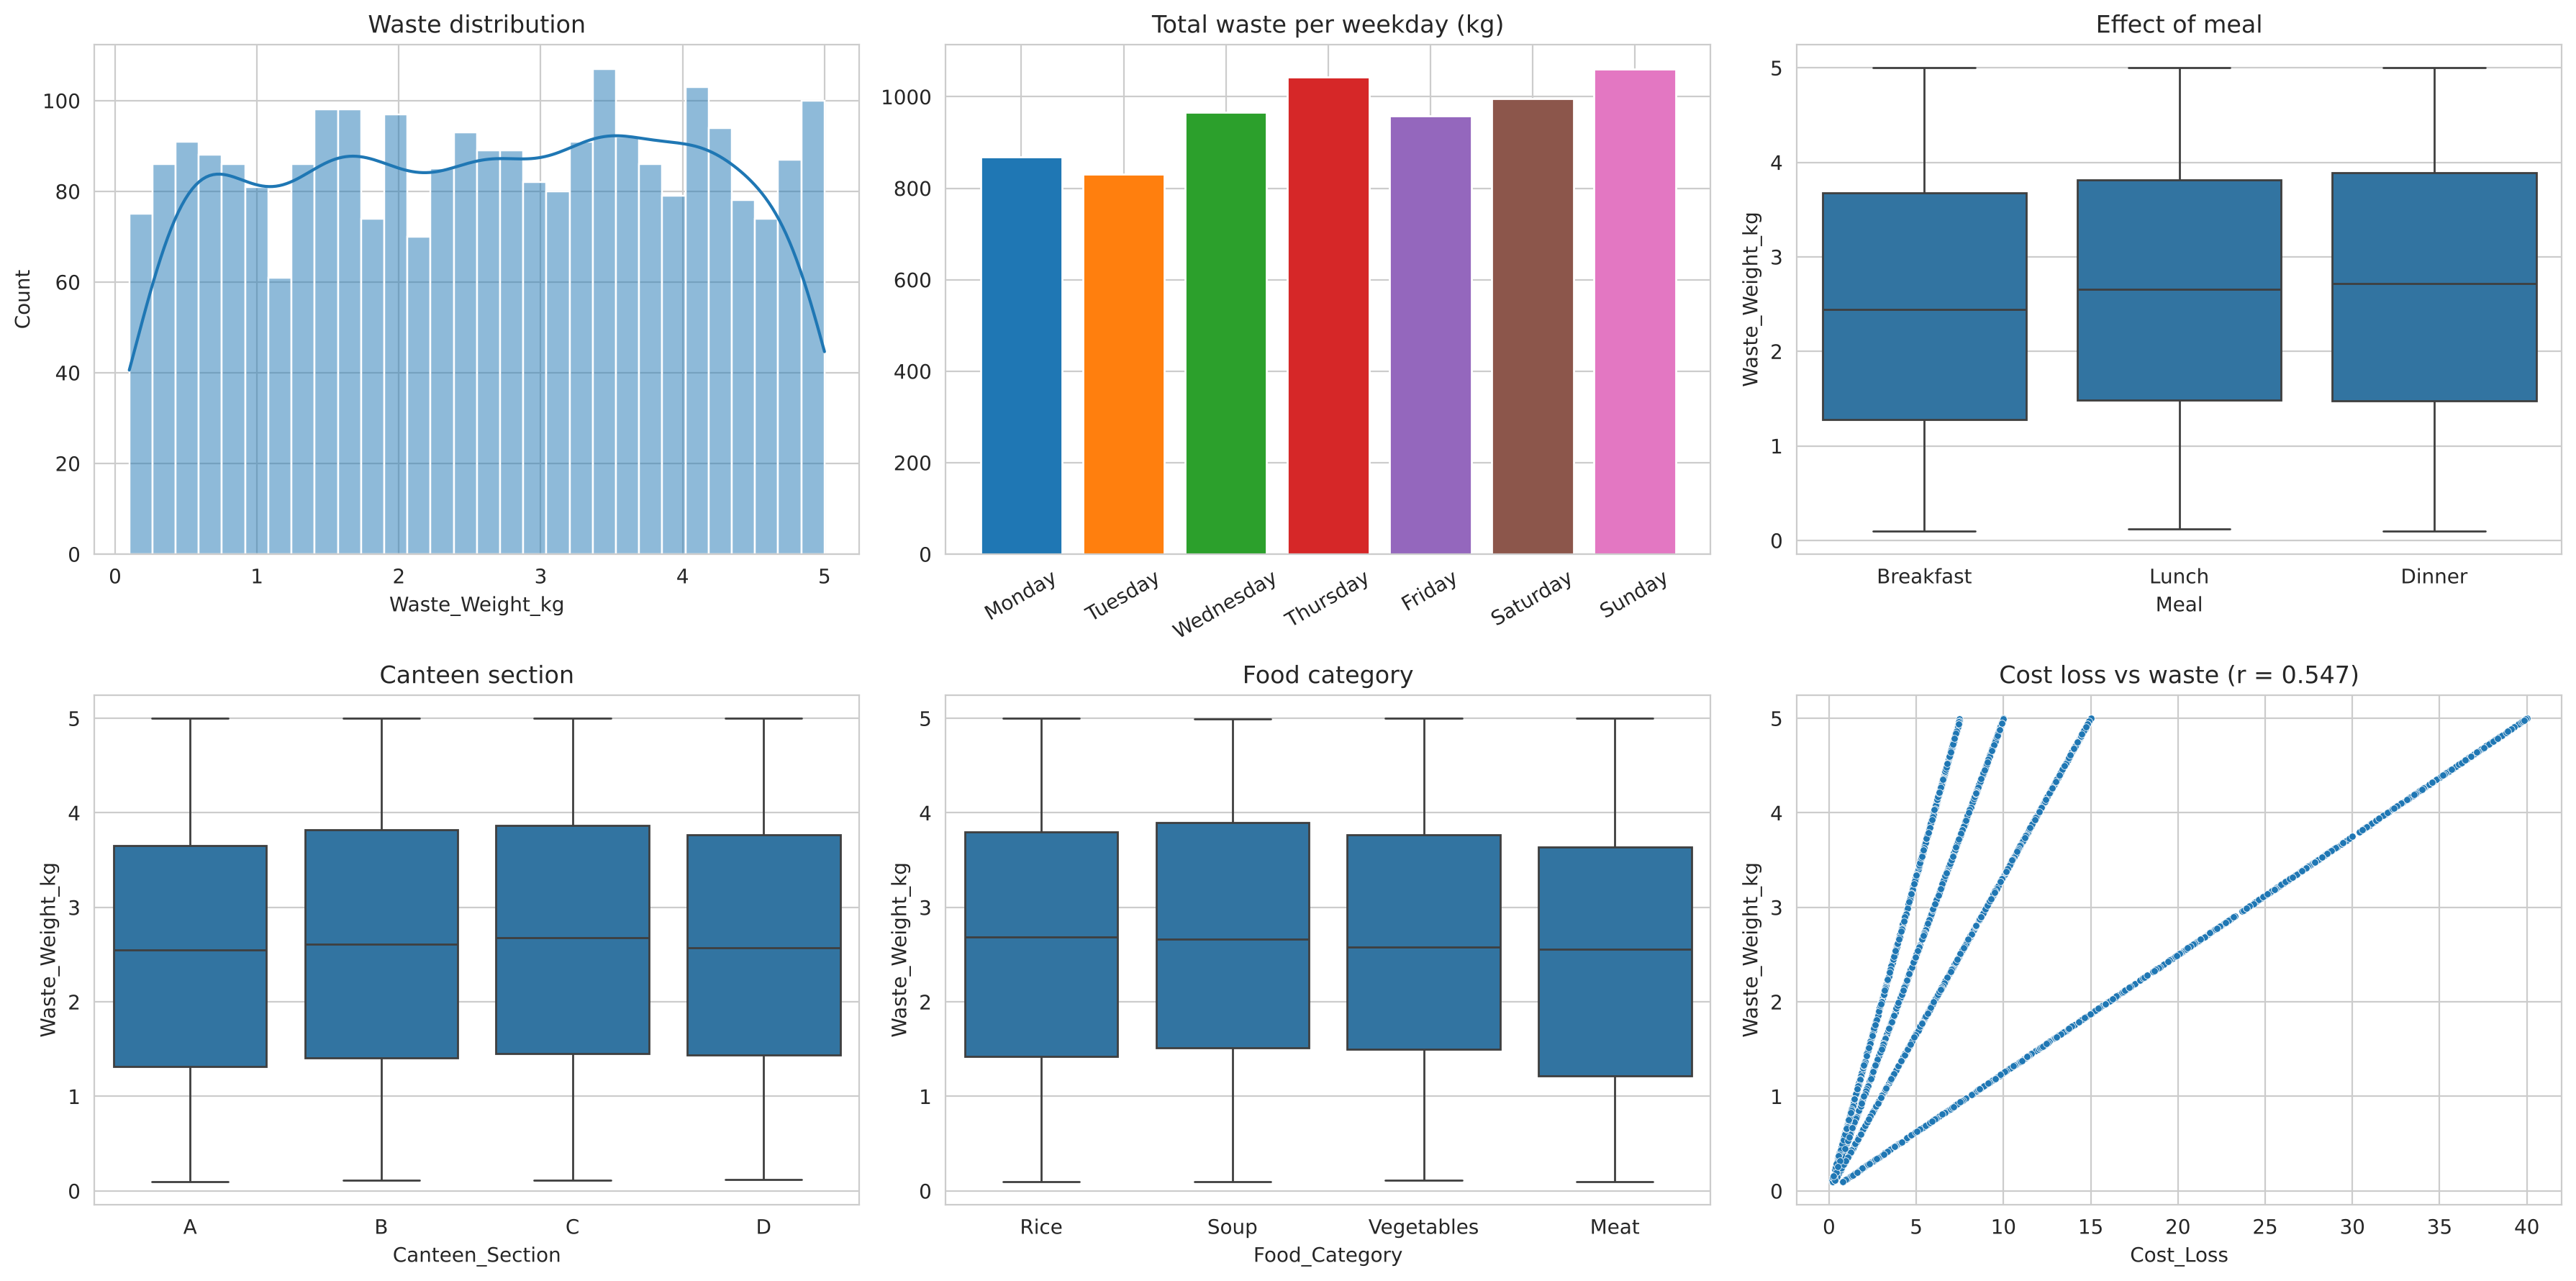

Week-of-month ANOVA: F = 1.221, p = 0.300 -> excluded (no meaningful effect)


In [6]:
DAYS  = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MEALS = ["Breakfast", "Lunch", "Dinner"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of waste per record
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Waste distribution")
# Total waste on each weekday
ax[0, 1].bar(DAYS, df.groupby("Day_of_Week")[TARGET].sum().reindex(DAYS), color=sns.color_palette("tab10", 7))
ax[0, 1].set_title("Total waste per weekday (kg)"); ax[0, 1].tick_params(axis="x", rotation=30)
# Waste by meal, canteen section and food category
sns.boxplot(data=df, x="Meal", y=TARGET, order=MEALS, ax=ax[0, 2]).set_title("Effect of meal")
sns.boxplot(data=df, x="Canteen_Section", y=TARGET, order=sorted(df.Canteen_Section.unique()), ax=ax[1, 0]).set_title("Canteen section")
sns.boxplot(data=df, x="Food_Category", y=TARGET, ax=ax[1, 1]).set_title("Food category")
# Cost loss against waste, with their correlation in the title
sns.scatterplot(data=df, x="Cost_Loss", y=TARGET, s=12, ax=ax[1, 2]).set_title(
    f"Cost loss vs waste (r = {df[['Cost_Loss', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

# One-way ANOVA: does mean waste differ between weeks of the month?
f, p = stats.f_oneway(*[g[TARGET].values for _, g in df.groupby("Week_of_Month")])
print(f"Week-of-month ANOVA: F = {f:.3f}, p = {p:.3f} -> {'excluded (no meaningful effect)' if p > 0.05 else 'significant'}")

## 4. Encoding, split and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split at random into 80 % training and 20 % testing. The split is made on row numbers rather than on the data itself, so Stacking 2 can look up each row's LSTM window (the 10 previous records of its series) and use exactly the same training and test rows as the other models.
3. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in kg.

In [7]:
CAT_COLS = ["Meal", "Canteen_Section", "Food_Category", "Day_of_Week", "Weekend_Status"]
NUM_COLS = ["Unit_Price_per_kg"] + (["Cost_Loss"] if USE_COST_LOSS else []) + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# Random 80/20 split on row positions, so LSTM windows can use the same rows
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

25 inputs | train (2080, 25) | test (520, 25)
['Unit_Price_per_kg', 'Cost_Loss', 'Waste_last_day', 'Waste_last_two_days', 'Waste_last_week', 'Meal_Breakfast', 'Meal_Dinner', 'Meal_Lunch', 'Canteen_Section_A', 'Canteen_Section_B', 'Canteen_Section_C', 'Canteen_Section_D', 'Food_Category_Meat', 'Food_Category_Rice', 'Food_Category_Soup', 'Food_Category_Vegetables', 'Day_of_Week_Friday', 'Day_of_Week_Monday', 'Day_of_Week_Saturday', 'Day_of_Week_Sunday', 'Day_of_Week_Thursday', 'Day_of_Week_Tuesday', 'Day_of_Week_Wednesday', 'Weekend_Status_Weekday', 'Weekend_Status_Weekend']


## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [8]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in kg / %), R2, training time and test-set size
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MAPE (%)": mape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to kg.

In [9]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to kg
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}  (18.2s)


XGBoost  {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100}  (3.9s)


SVR      {'regressor__C': 1, 'regressor__epsilon': 0.2}  (1.4s)


## 7. LSTM
Each sample is a window of the **10 preceding records of the same series** (all scaled inputs), and the label is the waste at the following record. The rows with 10 earlier records are split 80/20 with the same seed. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [10]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in kg.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

# Row numbers of the 10 previous records of each row's series. Records before a series' first record are
# padded by repeating that first record (only Stacking 2 needs that, because it must predict every row).
PREV = np.zeros((len(df), SEQ_LEN), dtype=int)
for rows in df.groupby(SERIES).indices.values():          # row numbers of one series, in time order
    for k, r in enumerate(rows):
        PREV[r] = rows[np.clip(np.arange(k - SEQ_LEN, k), 0, None)]
HISTORY = df.groupby(SERIES).cumcount().to_numpy()         # number of earlier records in the same series

def make_windows(days):
    # Window for row t = the 10 previous records of its series
    return np.stack([X_all[PREV[t]] for t in days])

# Complete windows only (rows with 10 earlier records in their series), split 80/20 with the same seed
days = np.where(HISTORY >= SEQ_LEN)[0]
W, yw = make_windows(days), y[days]
W_tr, W_te, yw_tr, yw_te = train_test_split(W, yw, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 12.8s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by an outer 5-fold grid search, which rebuilds the whole stack for every candidate value.

In [11]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions
stack = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                          final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
# Outer grid search over Ridge alpha; each candidate rebuilds and scores the whole stack
s1 = GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                  cv=CV_FOLDS, scoring=SCORING).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: {s1.best_params_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 1: {'final_estimator__alpha': 0.01} | Ridge weights [RF, XGB, SVR] = [0.778 0.223 0.003] (79.4s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking and grid-search procedure as Stacking 1, with the LSTM added as a fourth base model.
* Each row's input is `[row features | flattened 10-record window]`. Column selectors give RF, XGBoost and SVR the row features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "prefit"`, the LSTM is trained once on the training rows (included in the training time) and reused inside every fold. `"refit"` trains a new LSTM in every fold instead, which takes much longer.
* The prefit LSTM has already seen the training rows, so the cell after the model compares its accuracy on those rows with its accuracy on unseen test rows.

In [12]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "prefit"   # "prefit" = LSTM trained once and reused in every fold; "refit" = new LSTM trained in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-record windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 records, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the row's own features followed by its flattened 10-record window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [row features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on row features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model
stack2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)     # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2 = GridSearchCV(stack2, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                      cv=CV_FOLDS, scoring=SCORING).fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): {s2.best_params_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 2 (prefit): {'final_estimator__alpha': 0.01} | Ridge weights [RF, XGB, SVR, LSTM] = [0.778 0.222 0.003 0.001] (97.0s)


In [13]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({f"MAE ({UNIT})": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training rows (seen, fed to Ridge)", "Test rows (unseen)"]).round(3))

,MAE (kg),R2
"Training rows (seen, fed to Ridge)",1.214,0.019
Test rows (unseen),1.195,-0.004


## 10. Results
These are the test-set metrics for all six models. The LSTM is evaluated on its own test windows (the complete windows split separately); the other models on the test rows.

In [14]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,
RF,0.007,0.813,99.187,1.000,18.191,520
XGBoost,0.014,1.172,98.828,1.000,3.896,520
SVR,0.845,102.121,-2.121,0.435,1.433,520
LSTM,1.193,101.810,-1.810,-0.037,12.771,424
"Stacking 1 (RF, XGBoost, SVR)",0.007,0.757,99.243,1.000,79.407,520
"Stacking 2 (RF, XGBoost, SVR, LSTM)",0.007,0.757,99.243,1.000,96.998,520


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

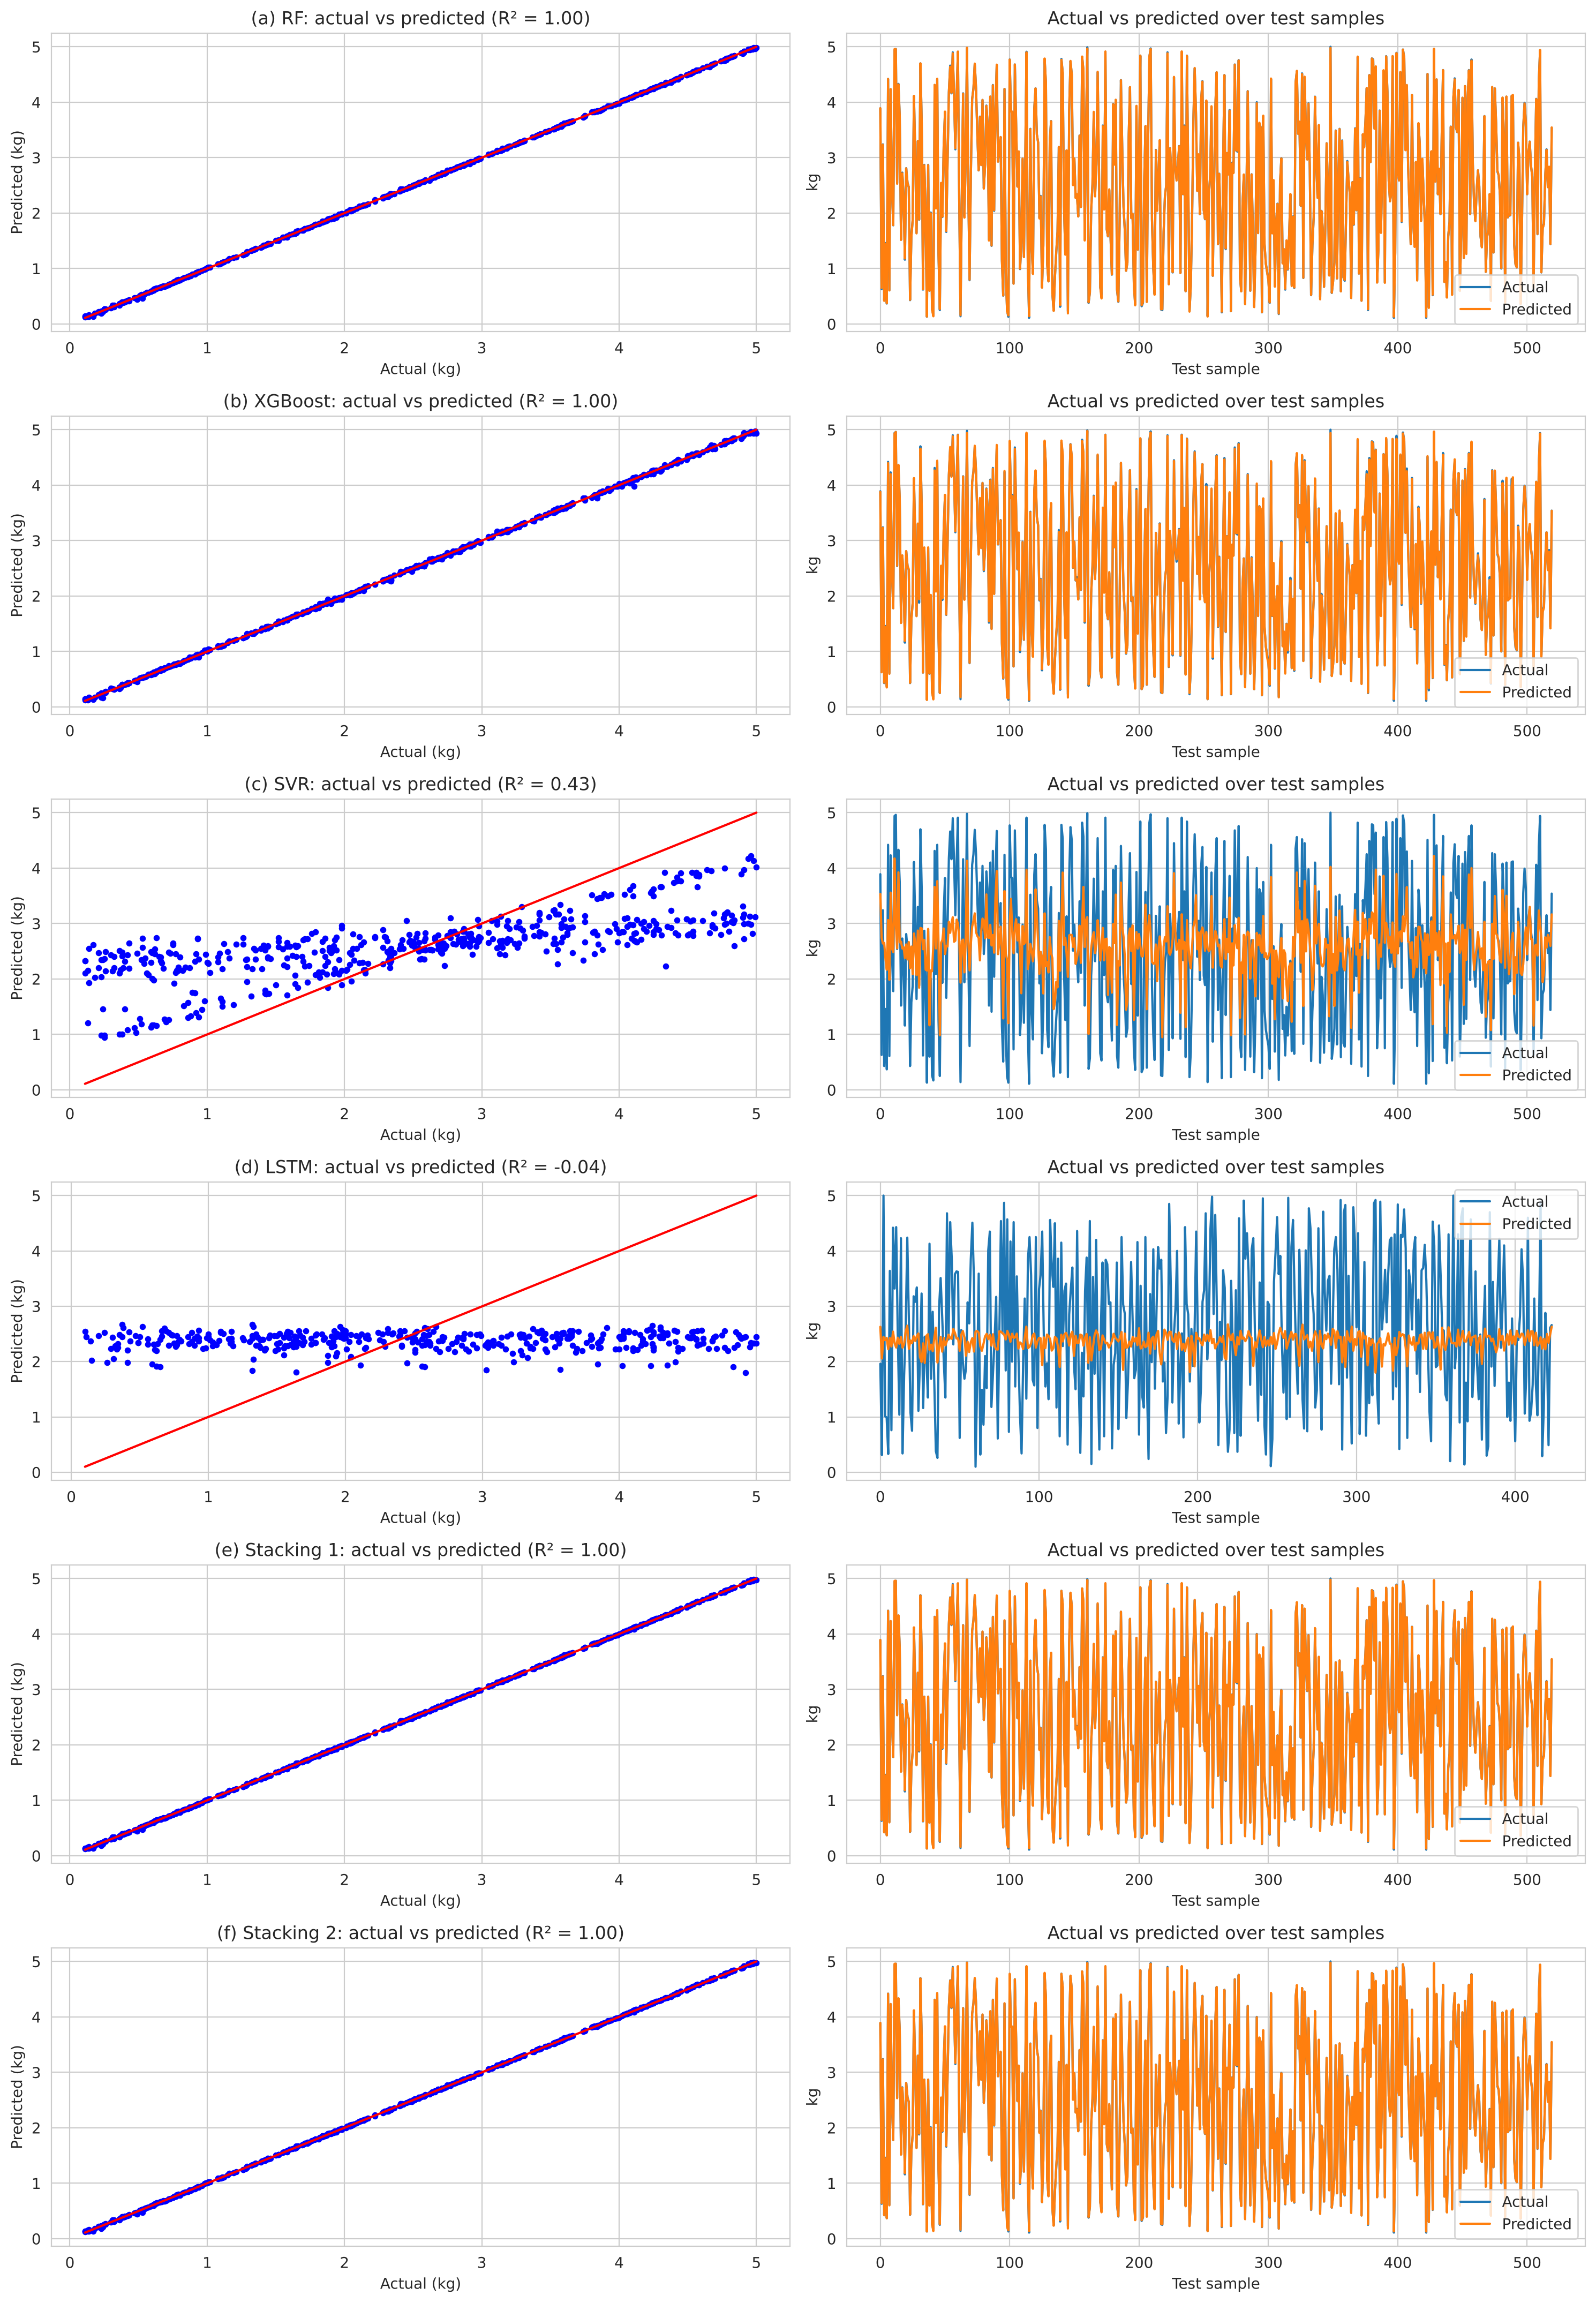

In [15]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdef'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

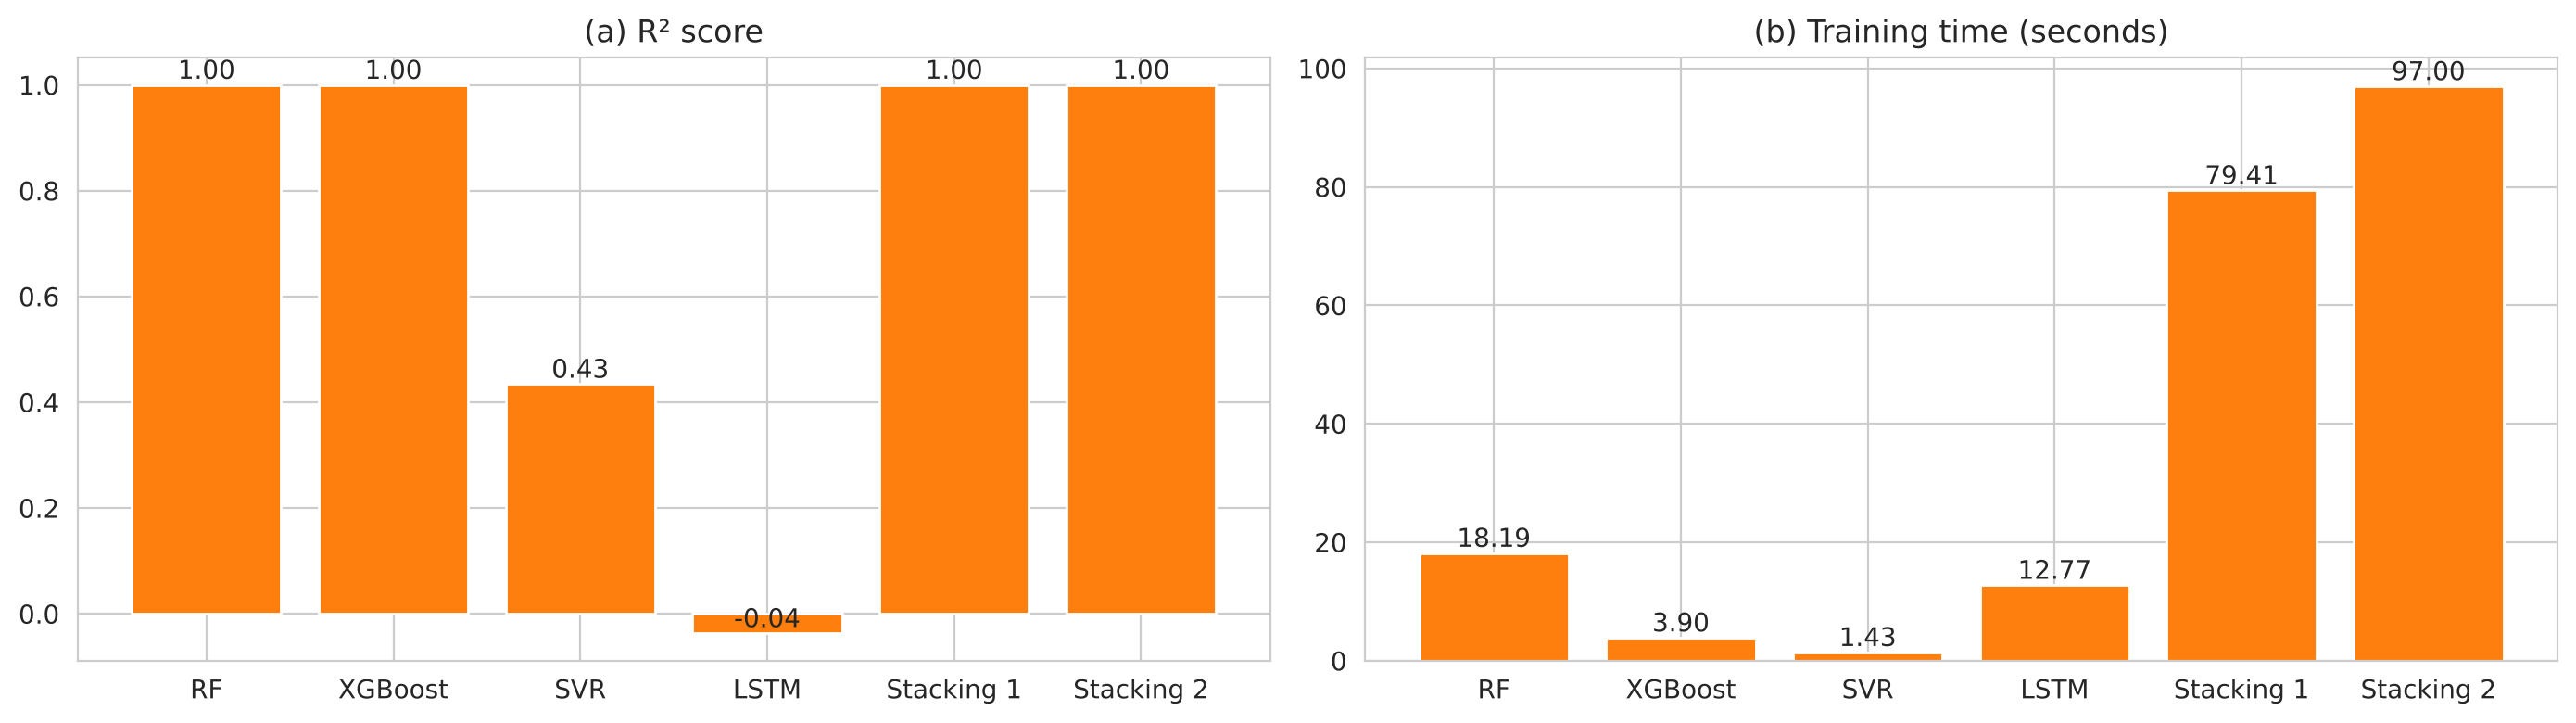

In [16]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()